<a href="https://colab.research.google.com/github/abina16/freecodecamp-health-costs-predictor/blob/main/freecodecamp_health_costs_predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import tensorflow as tf
from tensorflow import keras

## 1. Load and explore data

In [2]:
!wget https://cdn.freecodecamp.org/project-data/health-costs/insurance.csv
df = pd.read_csv("insurance.csv")
df.head()

--2026-10-20 17:45:53--  https://cdn.freecodecamp.org/project-data/health-costs/insurance.csv
Resolving cdn.freecodecamp.org (cdn.freecodecamp.org)... 104.26.3.33, 104.26.2.33, 172.67.70.149, ...
Connecting to cdn.freecodecamp.org (cdn.freecodecamp.org)|104.26.3.33|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 50264 (49K) [text/csv]
Saving to: ‘insurance.csv.1’

insurance.csv.1     100%[===================>]  49.09K  --.-KB/s    in 0.002s  

2026-10-20 17:45:53 (23.3 MB/s) - ‘insurance.csv.1’ saved [50264/50264]



,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86


In [3]:
df.shape

(1338, 7)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   expenses  1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
df.describe()

,age,bmi,children,expenses
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.665471,1.094918,13270.422414
std,14.049960,6.098382,1.205493,12110.011240
min,18.000000,16.000000,0.000000,1121.870000
25%,27.000000,26.300000,0.000000,4740.287500
50%,39.000000,30.400000,1.000000,9382.030000
75%,51.000000,34.700000,2.000000,16639.915000
max,64.000000,53.100000,5.000000,63770.430000


## 2. Convert text to numbers

In [6]:
#Kind 1: Yes/No options
df["sex"] = df["sex"].map({"female": 0, "male": 1})

In [7]:
df["smoker"] = df["smoker"].map({"yes":1, "no":0})

In [8]:
#Kind 2: More than 2 options
df = pd.get_dummies(df, columns=["region"], dtype=int)

In [9]:
df.head()

,age,sex,bmi,children,smoker,expenses,region_northeast,region_northwest,region_southeast,region_southwest
0,19,0,27.9,0,1,16884.92,0,0,0,1
1,18,1,33.8,1,0,1725.55,0,0,1,0
2,28,1,33.0,3,0,4449.46,0,0,1,0
3,33,1,22.7,0,0,21984.47,0,1,0,0
4,32,1,28.9,0,0,3866.86,0,1,0,0


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1338 non-null   int64  
 1   sex               1338 non-null   int64  
 2   bmi               1338 non-null   float64
 3   children          1338 non-null   int64  
 4   smoker            1338 non-null   int64  
 5   expenses          1338 non-null   float64
 6   region_northeast  1338 non-null   int64  
 7   region_northwest  1338 non-null   int64  
 8   region_southeast  1338 non-null   int64  
 9   region_southwest  1338 non-null   int64  
dtypes: float64(2), int64(8)
memory usage: 104.7 KB


## 3. Train/test split

In [11]:
train_dataset = df.sample(frac=0.8, random_state=42)
test_dataset = df.drop(train_dataset.index)

train_labels = train_dataset.pop("expenses")
test_labels = test_dataset.pop("expenses")

print(train_dataset.shape, train_labels.shape)
print(test_dataset.shape, test_labels.shape)

(1070, 9) (1070,)
(268, 9) (268,)


## 4. Build and train the model

In [12]:
norm = keras.layers.Normalization()
norm.adapt(train_dataset.to_numpy().astype("float32"))

In [13]:
model = keras.Sequential([
    keras.layers.Input(shape=(9,)),
    norm,
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(1)
])
model.compile(optimizer="adam",
              loss="mae",
              metrics=["mae"])

X_train = train_dataset.to_numpy().astype("float32")
X_test = test_dataset.to_numpy().astype("float32")

model.fit(X_train, train_labels, epochs=200, verbose=0)

test_loss, test_mae = model.evaluate(X_test, test_labels)
print("Off by about $", round(test_mae), "on average")

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2224.5234 - mae: 2224.5234  
Off by about $ 2225 on average


## 5. Results

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


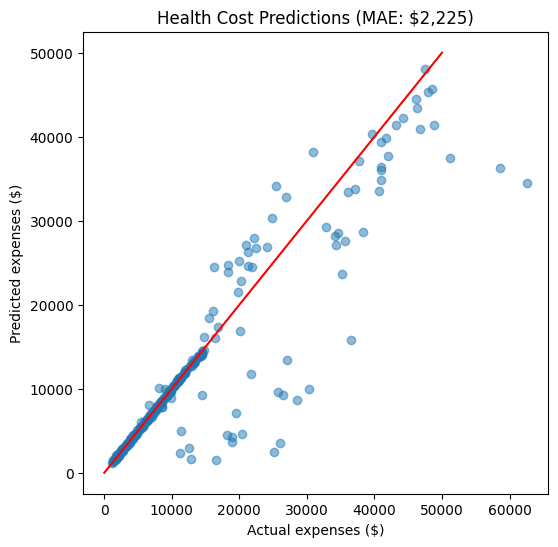

In [14]:
import matplotlib.pyplot as plt

predictions = model.predict(X_test).flatten()

plt.figure(figsize=(6, 6))
plt.scatter(test_labels, predictions, alpha=0.5)
plt.plot([0, 50000], [0, 50000], color="red")   # the "perfect guess" line
plt.xlabel("Actual expenses ($)")
plt.ylabel("Predicted expenses ($)")
plt.title(f"Health Cost Predictions (MAE: ${test_mae:,.0f})")
plt.show()